# Developed-Markets Equity Scorecard — final deliverable (v12)
**Question:** which of US, Eurozone, UK, Switzerland and Japan will outperform the others over the next 3–6 months?

**Two views, deliberately kept separate**
| View | Purpose | Contents |
|---|---|---|
| **Diagnostic scorecard** | Describe each market across the four pillars the brief asks for | Macro, Micro, Valuation, Technical — each labelled with its validation status |
| **Predictive score** | Rank markets for allocation | **Macro FCI 6M only** — the one signal with timing evidence that survives the v11 audit |

Research history (v1–v11), including every rejected idea, is in the repo. This notebook only builds the final products. Audit: `output/v11/AUDIT_REPORT.md`.

**Evidence standard:** no signal here is statistically significant after accounting for the search that found it. The predictive score is a **provisional** candidate, not a validated edge.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, json
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import rankdata
from IPython.display import display
warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:,.3f}'.format; pd.options.display.width = 220
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
ROOT = Path('..').resolve(); OUT = ROOT/'output'/'v12'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)
COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']; SEED = 7

## 1. Data
Only the workbooks supplied with the assignment are used. One observation per market per month (the last in the month).

In [2]:
SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', fci=('GSFCI Index', -1),   fx=None),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    fci=('BFCIEU Index', +1),  fx=('EURUSD BGN Curncy', 'direct')),
 'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    fci=('GSGBFCI Index', -1), fx=('GBPUSD BGN Curncy', 'direct')),
 'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    fci=('GSEAFCI Index', -1), fx=('USDCHF Curncy', 'invert')),
 'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    fci=('GSJPFCI Index', -1), fx=('USDJPY BGN Curncy', 'invert')),
}
def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    return d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')
def load(c):
    s = SPEC[c]; d = monthly(pd.read_excel(ROOT/'data'/'raw'/s['file']))
    o = pd.DataFrame({'date': pd.to_datetime(d['Date']).dt.date, 'pe': d['BEst P/E Ratio'], 'eps': d[s['eps']], 'fci_raw': d[s['fci'][0]]})
    o['fci'] = s['fci'][1] * o['fci_raw']                       # oriented: higher = EASIER financing conditions
    o['usd_per_local'] = 1.0 if s['fx'] is None else (d[s['fx'][0]] if s['fx'][1] == 'direct' else 1.0 / d[s['fx'][0]])
    return o
fr = {c: load(c) for c in COUNTRIES}
IDX = pd.period_range(max(fr[c].pe.first_valid_index() for c in COUNTRIES), min(fr[c].index.max() for c in COUNTRIES), freq='M')
PE, EPS, FCI, FX = [pd.DataFrame({c: fr[c][k] for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'fci', 'usd_per_local')]
PX = PE * EPS                     # implied index level = P/E x forward EPS (accounting identity; matches S&P 500 returns, v4)
PX_USD = PX * FX; R_USD = PX_USD.pct_change()
AS_OF = IDX[-1]
cov = pd.DataFrame({'file': {c: SPEC[c]['file'] for c in COUNTRIES}, 'EPS field': {c: SPEC[c]['eps'] for c in COUNTRIES}, 'FCI series': {c: SPEC[c]['fci'][0] for c in COUNTRIES},
                    'first month': {c: str(fr[c].pe.first_valid_index()) for c in COUNTRIES}, 'last date in file': {c: str(fr[c].date.iloc[-1]) for c in COUNTRIES}})
display(cov)
print(f'Panel used for every result: {IDX[0]} -> {AS_OF} ({len(IDX)} months). As-of date = last month in which ALL five markets report: {AS_OF} (US file ends 2026-04-30).')
print('Later readings exist for EZ/JP (to 2026-06) and UK/CH (to 2026-07); they cannot enter a 5-market ranking and are shown separately in section 6 as information only.')
# CSV input: the exact monthly panel every result is built from
panel = pd.concat({'PE': PE, 'EPS_fwd': EPS, 'FCI_oriented_easier_plus': FCI, 'USD_per_local': FX, 'implied_price_local': PX, 'implied_price_usd': PX_USD}, axis=1)
panel.index = panel.index.astype(str); panel.to_csv(OUT/'input_monthly_panel.csv')
print('Wrote input_monthly_panel.csv', panel.shape)

,file,EPS field,FCI series,first month,last date in file
US,US_raw_data.xlsx,Monthly_EPS,GSFCI Index,2005-01,2026-04-30
Eurozone,EUR_raw_data.xlsx,BEst EPS,BFCIEU Index,2005-12,2026-06-29
UK,UK_raw_data.xlsx,BEst EPS,GSGBFCI Index,2005-12,2026-07-02
Switzerland,CH_raw_data.xlsx,BEst EPS,GSEAFCI Index,2005-12,2026-07-14
Japan,JPY_raw_data.xlsx,BEst EPS,GSJPFCI Index,2005-06,2026-06-29


Panel used for every result: 2005-12 -> 2026-04 (245 months). As-of date = last month in which ALL five markets report: 2026-04 (US file ends 2026-04-30).
Later readings exist for EZ/JP (to 2026-06) and UK/CH (to 2026-07); they cannot enter a 5-market ranking and are shown separately in section 6 as information only.
Wrote input_monthly_panel.csv (245, 30)


## 2. Signals, target and test machinery
| Pillar | Indicator | Formula (month-end t) | Direction |
|---|---|---|---|
| Macro | FCI 6M easing | $(FCI_t-FCI_{t-6})/\text{sd}_{\le t}$ (expanding sd of the 6M change, ≥36 obs) | easier ⇒ + |
| Micro | EPS revision 6M | $EPS_t/EPS_{t-6}-1$ (forward consensus EPS) | upgrades ⇒ + |
| Valuation | P/E vs peers | $-z_{\le t}(PE_t/\overline{PE}_t)$ (expanding z, ≥60 obs) | cheap ⇒ + |
| Technical | Low realised vol 12M | $-\text{sd}(r_{t-11..t})$ of local monthly returns | low vol ⇒ + |

Each indicator is z-scored **across the five markets** each month. **Target:** USD price return from month-end t to t+h, minus the five-market average (h = 3, 6).
**Split:** discovery ≤ 2016-12 · 6-month embargo · validation ≥ 2017-07. Each indicator is evaluated on every month in which it is defined (no gaps).

In [3]:
cs_z = lambda d: d.sub(d.mean(axis=1), axis=0).div(d.std(axis=1, ddof=1), axis=0).where(d.notna().all(axis=1))
own_sd = lambda d, w=36: d / d.expanding(w).std()
z_own = lambda x, w=60: (x - x.expanding(w).mean()) / x.expanding(w).std()
RAW = {'Macro': own_sd(FCI - FCI.shift(6)), 'Micro': EPS / EPS.shift(6) - 1,
       'Valuation': -z_own(PE.div(PE.mean(axis=1), axis=0)), 'Technical': -PX.pct_change().rolling(12).std()}
NAME = {'Macro': 'FCI 6M easing', 'Micro': 'EPS revision 6M', 'Valuation': 'P/E vs peers (cheap +)', 'Technical': 'Low realised vol 12M'}
Z = {p: cs_z(v) for p, v in RAW.items()}
def fwd(h): r = PX_USD.shift(-h) / PX_USD - 1; return r.sub(r.mean(axis=1), axis=0)
TGT = {h: fwd(h) for h in (3, 6)}
EMB_END, VAL_START = pd.Period('2016-12', 'M'), pd.Period('2017-07', 'M')
def ric(S, Y):
    s = S.to_numpy(float); y = Y.reindex(S.index).to_numpy(float); ok = ~np.isnan(s).any(1) & ~np.isnan(y).any(1)
    rs = rankdata(s[ok], axis=1); ry = rankdata(y[ok], axis=1); rs -= rs.mean(1, keepdims=True); ry -= ry.mean(1, keepdims=True)
    den = np.sqrt((rs**2).sum(1) * (ry**2).sum(1))
    return pd.Series(np.where(den > 0, (rs * ry).sum(1) / np.where(den > 0, den, 1), np.nan), index=S.index[ok]).dropna()
def hac_t(x, lags):
    x = np.asarray(x, float); m = sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}); return float(m.tvalues[0])
def perm_p(S, Y, months, h, n=5000, seed=SEED):
    """block permutation: shuffle country labels of the target in h-month blocks; one-sided add-one p"""
    s = S.reindex(months).to_numpy(float); y = Y.reindex(months).to_numpy(float)
    ur = lambda A: (lambda r: r / np.sqrt((r**2).sum(-1, keepdims=True)))(rankdata(A, axis=-1) - 3.0)
    RS, RY = ur(s), ur(y); T = len(months); blk = np.arange(T) // h
    P = np.random.default_rng(seed).permuted(np.tile(np.arange(5), (n, blk.max() + 1, 1)), axis=2)[:, blk, :]
    null = (RS[None] * np.take_along_axis(np.broadcast_to(RY, (n, T, 5)), P, axis=2)).sum(-1).mean(-1)
    obs = (RS * RY).sum(-1).mean(); return (1 + (null >= obs).sum()) / (1 + n)

## 3. Signal selection and predictive power
Rank IC per month (Spearman across the five markets), averaged. HAC t uses lags = horizon. `perm p` = block permutation of country labels (5,000 draws), one-sided, add-one.
**How to read the t-stats:** the v11 size simulation showed that, in samples this short with overlapping returns, a nominal 5% HAC test rejects 6–9% of the time; the empirical one-sided 5% critical value is **≈1.8–2.0**, not 1.645. And these signals were chosen from a larger family: the best-of-family p-values are 0.16–0.20 (v11 §6f).

In [4]:
rows = []
for p, z in Z.items():
    for h in (3, 6):
        ic = ric(z, TGT[h]); d = ic[ic.index <= EMB_END]; v = ic[ic.index >= VAL_START]
        rows.append({'pillar': p, 'indicator': NAME[p], 'horizon': f'{h}M', 'first month': str(ic.index.min()),
                     'disc IC': d.mean(), 'disc t': hac_t(d.values, h), 'val IC': v.mean(), 'val t': hac_t(v.values, h),
                     'val perm p': perm_p(z, TGT[h], v.index, h), 'full IC': ic.mean(), 'full t': hac_t(ic.values, h), 'val months': len(v)})
EVID = pd.DataFrame(rows).set_index(['pillar', 'horizon'])
STATUS = {'Macro': ('PROVISIONAL — predictive', 'Positive in validation at 3M and 6M; survives removal of each market’s average return (timing t 1.91 at 6M); ex-US holds at 6M (t 1.92) but not at 3M (t 0.72); not significant after family selection.'),
          'Micro': ('PROVISIONAL — diagnostic only', 'Positive at 3M, weak at 6M; ~45% of the 3M IC is a static tilt toward the US and Japan (timing-only IC +0.072, t 0.99); adds nothing to FCI in validation.'),
          'Valuation': ('REJECTED — context only', 'Negative in validation; harmful when added to FCI+EPS (ΔIC t −3.3). Cheap markets stay cheap: the earnings leg offsets the re-rating.'),
          'Technical': ('REJECTED — context only', 'Sign flips from discovery to validation; not explained by market direction; no country-level mechanism identified.')}
EVID['status'] = [STATUS[p][0] for p, _ in EVID.index]
display(EVID.drop(columns='status').style.format({'disc IC': '{:+.3f}', 'val IC': '{:+.3f}', 'full IC': '{:+.3f}', 'disc t': '{:+.2f}', 'val t': '{:+.2f}', 'full t': '{:+.2f}', 'val perm p': '{:.3f}'}))
display(pd.DataFrame({p: {'indicator': NAME[p], 'status': s[0], 'why': s[1]} for p, s in STATUS.items()}).T)
EVID.to_csv(OUT/'signal_evidence.csv')

,indicator,status,why
Macro,FCI 6M easing,PROVISIONAL — predictive,Positive in validation at 3M and 6M; survives ...
Micro,EPS revision 6M,PROVISIONAL — diagnostic only,"Positive at 3M, weak at 6M; ~45% of the 3M IC ..."
Valuation,P/E vs peers (cheap +),REJECTED — context only,Negative in validation; harmful when added to ...
Technical,Low realised vol 12M,REJECTED — context only,Sign flips from discovery to validation; not e...


## 4. Scorecard construction
* **Pillar score** = the indicator's cross-sectional z-score (one indicator per pillar — the audit found no evidence that adding variants helps).
* **Diagnostic aggregate** = equal-weight average of the four pillar scores. This is what the brief's four-pillar structure produces; it is **reported, not used for allocation**.
* **Predictive score** = the Macro pillar alone (FCI 6M), horizon 6M.
* **Ranking** = 1 (most attractive) … 5.

In [5]:
DIAG = pd.concat([Z[p] for p in Z]).groupby(level=0).mean().reindex(IDX).where(pd.concat([Z[p].notna().all(axis=1) for p in Z], axis=1).all(axis=1), axis=0)
PRED = Z['Macro']
long = []
for t in IDX:
    for c in COUNTRIES:
        long.append({'month': str(t), 'country': c, **{f'{p} score': Z[p].loc[t, c] for p in Z},
                     'diagnostic aggregate': DIAG.loc[t, c], 'predictive score (FCI 6M)': PRED.loc[t, c]})
SC = pd.DataFrame(long)
SC['diagnostic rank'] = SC.groupby('month')['diagnostic aggregate'].rank(ascending=False)
SC['predictive rank'] = SC.groupby('month')['predictive score (FCI 6M)'].rank(ascending=False)
SC.to_csv(OUT/'output_monthly_scores.csv', index=False)
print(f'Diagnostic aggregate defined from {DIAG.dropna().index.min()} (60M history needed for the P/E z-score); predictive score from {PRED.dropna().index.min()}.')
ic_d = {h: ric(DIAG, TGT[h]) for h in (3, 6)}
print('Diagnostic aggregate IC - validation: ' + ', '.join(f'{h}M {ic_d[h][ic_d[h].index >= VAL_START].mean():+.3f} (t {hac_t(ic_d[h][ic_d[h].index >= VAL_START].values, h):+.2f})' for h in (3, 6))
      + '  -> forcing four pillars costs predictive power, which is why it is not the allocation signal.')

Diagnostic aggregate defined from 2010-11 (60M history needed for the P/E z-score); predictive score from 2009-05.
Diagnostic aggregate IC - validation: 3M -0.037 (t -0.55), 6M -0.032 (t -0.44)  -> forcing four pillars costs predictive power, which is why it is not the allocation signal.


## 5. Backtest
**Rules (fixed before running; unchanged from v7–v10 except the 6-month hold agreed for v12):**
* Signal at month-end t; trade at month-end t; earn month t+1 USD price return (no dividends — see limitations).
* **Long-short:** +50% in each of the top-2 markets, −50% in each of the bottom-2; the middle market is flat.
* **Long-only:** 50% in each of the top-2; benchmark = 20% in each of the five (equal weight). Active = long-only − benchmark.
* **6-month overlapping tranches:** each month a new 1/6 tranche is formed and held 6 months, so holdings = average of the last six target portfolios. Tranches are held at constant weight (monthly re-weighted), the standard convention.
* **Costs:** one-way cost × turnover, turnover = Σ|Δweight| each month (both legs counted). Grid 0 / 5 / 10 / 20 bps. Benchmark carried cost-free.
* Windows: **common** (both strategies live) and **validation** (return months ≥ 2017-08).

In [6]:
H = 6; COSTS = (0, 5, 10, 20)
def tgt_weights(score, kind):
    ok = score.notna().all(axis=1); rk = score[ok].rank(axis=1, ascending=False)
    w = (rk <= 2) * 0.5 - ((rk >= 4) * 0.5 if kind == 'LS' else 0)
    return w.astype(float).rolling(H, min_periods=1).mean()
def run(score, kind):
    w = tgt_weights(score, kind)
    turn = w.diff().abs().sum(axis=1); turn.iloc[0] = w.iloc[0].abs().sum()
    gross = (w.shift(1) * R_USD.reindex(w.index)).sum(axis=1, min_count=5).iloc[1:]
    return w, gross, turn.shift(1).iloc[1:]           # cost of the trade at t is paid in the t+1 return
def stats(r, turn=None, bps=0):
    net = r - (turn * bps * 1e-4 if turn is not None else 0)
    cum = (1 + net).cumprod(); dd = cum / cum.cummax() - 1
    pos, neg = net[net > 0].sum(), -net[net < 0].sum()
    return {'Return % p.a.': ((cum.iloc[-1]) ** (12 / len(net)) - 1) * 100, 'Sharpe': net.mean() / net.std() * np.sqrt(12),
            'Max drawdown %': dd.min() * 100, 'Win rate (months) %': (net > 0).mean() * 100, 'Profit factor': pos / neg if neg > 0 else np.nan,
            'Turnover p.a. (x)': turn.mean() * 12 if turn is not None else 0.0, 'Cost drag % p.a.': (turn.mean() * 12 * bps * 1e-2) if turn is not None else 0.0}
STRATS = {'Predictive (FCI 6M)': PRED, 'Diagnostic 4-pillar (comparison)': DIAG}
RES = {}
for nm, sc in STRATS.items():
    for kind in ('LS', 'LO'):
        RES[(nm, kind)] = run(sc, kind)
bench = R_USD.mean(axis=1)
start = max(RES[k][1].index.min() for k in RES)
WINS = {f'common {start}..{AS_OF}': (start, AS_OF), f'validation 2017-08..{AS_OF}': (pd.Period('2017-08', 'M'), AS_OF)}
rows = []
for wl, (a, b) in WINS.items():
    sl = lambda s: s[(s.index >= a) & (s.index <= b)]
    rows.append({'window': wl, 'strategy': 'Equal-weight benchmark (5 markets)', 'book': 'long-only', 'cost bps': 0, 'months': len(sl(bench)), **stats(sl(bench))})
    for (nm, kind), (w, g, tn) in RES.items():
        for bps in COSTS:
            if kind == 'LS':
                rows.append({'window': wl, 'strategy': nm, 'book': 'long-short', 'cost bps': bps, 'months': len(sl(g)), **stats(sl(g), sl(tn), bps)})
            else:
                rows.append({'window': wl, 'strategy': nm, 'book': 'long-only (absolute)', 'cost bps': bps, 'months': len(sl(g)), **stats(sl(g), sl(tn), bps)})
                rows.append({'window': wl, 'strategy': nm, 'book': 'long-only ACTIVE vs EW', 'cost bps': bps, 'months': len(sl(g)), **stats(sl(g) - sl(bench.reindex(g.index)), sl(tn), bps)})
BT = pd.DataFrame(rows).set_index(['window', 'strategy', 'book', 'cost bps'])
fmB = {'Return % p.a.': '{:+.2f}', 'Sharpe': '{:+.2f}', 'Max drawdown %': '{:.1f}', 'Win rate (months) %': '{:.0f}', 'Profit factor': '{:.2f}', 'Turnover p.a. (x)': '{:.2f}', 'Cost drag % p.a.': '{:.2f}'}
display(BT.style.format(fmB))
BT.to_csv(OUT/'backtest_summary.csv')
MR = pd.DataFrame({'EW benchmark': bench} | {f'{nm} | {k} gross': RES[(nm, k)][1] for nm, k in RES} | {f'{nm} | {k} turnover': RES[(nm, k)][2] for nm, k in RES})
MR.index = MR.index.astype(str); MR.to_csv(OUT/'output_backtest_monthly.csv')

### Is the long-short return distinguishable from zero, and who drives it?

In [7]:
def mbb_p(x, L=12, n=5000, seed=SEED):
    x = np.asarray(x, float); T = len(x); rng = np.random.default_rng(seed); nb = int(np.ceil(T / L))
    st = rng.integers(0, T - L + 1, (n, nb)); idx = (st[:, :, None] + np.arange(L)).reshape(n, -1)[:, :T]; m = x[idx].mean(1)
    return (1 + ((m - m.mean()) >= x.mean()).sum()) / (1 + n), np.percentile(m, [2.5, 97.5])
rows = []
for wl, (a, b) in WINS.items():
    for nm in STRATS:
        w, g, tn = RES[(nm, 'LS')]; net = (g - tn * 10e-4)[(g.index >= a) & (g.index <= b)]
        p, ci = mbb_p(net.values)
        contrib = (w.shift(1) * R_USD).reindex(net.index).mean() * 1200
        rows.append({'window': wl, 'strategy': nm, 'mean net % p.a. (10 bps)': net.mean() * 1200, 'boot 95% CI % p.a.': f'[{ci[0]*1200:+.2f}, {ci[1]*1200:+.2f}]',
                     'block-boot p (L=12)': p, 'HAC t (12 lags)': hac_t(net.values, 12), **{f'{c} contrib % p.a.': contrib[c] for c in COUNTRIES},
                     **{f'{c} % months long': (w.shift(1).reindex(net.index)[c] > 0).mean() * 100 for c in COUNTRIES}})
SIG = pd.DataFrame(rows).set_index(['window', 'strategy'])
display(SIG.style.format({c: '{:+.2f}' for c in SIG.columns if '% p.a.' in c and 'CI' not in c} | {'block-boot p (L=12)': '{:.3f}', 'HAC t (12 lags)': '{:+.2f}'} | {c: '{:.0f}' for c in SIG.columns if 'months long' in c}))
SIG.to_csv(OUT/'backtest_significance_attribution.csv')
print('Bootstrap/HAC p-values here inherit the over-rejection documented in v11 and ignore the selection of the signal: treat as descriptive.')

Bootstrap/HAC p-values here inherit the over-rejection documented in v11 and ignore the selection of the signal: treat as descriptive.


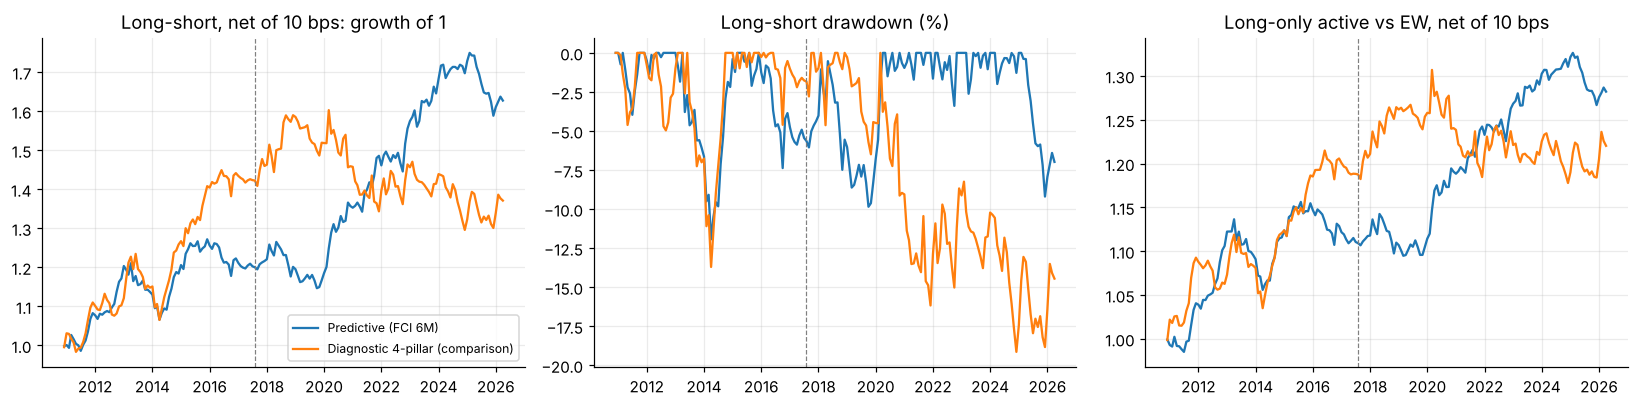

Dashed line = start of the validation window.


In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for nm, col in zip(STRATS, ('C0', 'C1')):
    g, tn = RES[(nm, 'LS')][1:]; net = (g - tn * 10e-4)[g.index >= start]; cum = (1 + net).cumprod()
    axs[0].plot(cum.index.to_timestamp(), cum.values, col, label=nm); axs[1].plot(cum.index.to_timestamp(), (cum / cum.cummax() - 1).values * 100, col, label=nm)
    g2, tn2 = RES[(nm, 'LO')][1:]; act = ((g2 - tn2 * 10e-4) - bench.reindex(g2.index)); act = act[act.index >= start]
    axs[2].plot(act.index.to_timestamp(), (1 + act).cumprod().values, col, label=nm)
for ax, t_ in zip(axs, ('Long-short, net of 10 bps: growth of 1', 'Long-short drawdown (%)', 'Long-only active vs EW, net of 10 bps')):
    ax.set_title(t_); ax.axvline(pd.Timestamp('2017-07-31'), c='grey', ls='--', lw=.8)
axs[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(CH/'backtest.png', bbox_inches='tight'); plt.show()
print('Dashed line = start of the validation window.')

## 6. Current rankings — as of the latest common data date
The as-of month is the last month in which **all five** markets have data. Nothing after it is used, and nothing is extrapolated to the present.

In [9]:
t = AS_OF
print(f'AS-OF: {t} (file dates: ' + ', '.join(f'{c} {fr[c].date.loc[t]}' for c in COUNTRIES) + ')')
w_ls = RES[('Predictive (FCI 6M)', 'LS')][0]; w_lo = RES[('Predictive (FCI 6M)', 'LO')][0]
CUR = pd.DataFrame({
    'FCI 6M change (oriented, raw units)': (FCI - FCI.shift(6)).loc[t],
    'FCI 6M easing (own-sd units)': RAW['Macro'].loc[t],
    'EPS revision 6M %': RAW['Micro'].loc[t] * 100,
    'P/E': PE.loc[t], 'P/E / peer avg': (PE.div(PE.mean(axis=1), axis=0)).loc[t],
    '12M realised vol % (ann.)': PX.pct_change().rolling(12).std().loc[t] * np.sqrt(12) * 100})
display(CUR.style.format('{:+.2f}'))
RANK = pd.DataFrame({f'{p} score': Z[p].loc[t] for p in Z})
RANK['Diagnostic aggregate'] = DIAG.loc[t]; RANK['Diagnostic rank'] = RANK['Diagnostic aggregate'].rank(ascending=False).astype(int)
RANK['PREDICTIVE score (FCI 6M)'] = PRED.loc[t]; RANK['PREDICTIVE rank'] = RANK['PREDICTIVE score (FCI 6M)'].rank(ascending=False).astype(int)
RANK['new tranche (L/S)'] = RANK['PREDICTIVE rank'].map(lambda r: 'LONG' if r <= 2 else ('SHORT' if r >= 4 else 'flat'))
RANK['held weight L/S (6 tranches)'] = w_ls.loc[t] * 100; RANK['held weight long-only %'] = w_lo.loc[t] * 100
RANK['active vs EW %'] = RANK['held weight long-only %'] - 20
RANK = RANK.sort_values('PREDICTIVE rank')
display(RANK.style.format({c: '{:+.2f}' for c in RANK.columns if 'score' in c or 'aggregate' in c} | {c: '{:+.0f}' for c in RANK.columns if 'weight' in c or 'active' in c}))
RANK.to_csv(OUT/'output_current_ranking.csv')
hist = pd.DataFrame({str(m): PRED.loc[m].rank(ascending=False).astype(int) for m in IDX[-6:]}).T
print('Predictive rank over the six months whose tranches are currently held (1 = most attractive):'); display(hist)
hist.to_csv(OUT/'output_predictive_rank_last6.csv')
disp = RAW['Macro'].std(axis=1).dropna(); pct = (disp <= disp.loc[t]).mean()
flips = (hist.diff().abs().sum(axis=1).iloc[1:]).mean()
print(f'Cross-market spread of the FCI reading at {t}: {disp.loc[t]:.2f} own-sd units (percentile {pct:.0%} of 2009-2026).')
print(f'Average total rank change per month over the last six months: {flips:.1f} rank places (out of a maximum of 12).')
print('Context only: v10 (test C01) found no evidence that the FCI IC rises with cross-market dispersion, so dispersion is not used to scale conviction.')
print('HELD BOOK vs NEW SIGNAL: under the 6M tranche rule the book is the average of the last six target portfolios; the April signal reverses several of them.')

AS-OF: 2026-04 (file dates: US 2026-04-30, Eurozone 2026-04-30, UK 2026-04-30, Switzerland 2026-04-30, Japan 2026-04-30)


,"FCI 6M change (oriented, raw units)",FCI 6M easing (own-sd units),EPS revision 6M %,P/E,P/E / peer avg,12M realised vol % (ann.)
US,+0.01,+0.01,+16.47,+20.70,+1.23,+13.33
Eurozone,-0.18,-0.13,+7.25,+14.85,+0.88,+12.48
UK,-0.30,-0.46,+11.69,+12.89,+0.76,+11.29
Switzerland,-0.05,-0.12,+1.43,+18.33,+1.09,+13.04
Japan,-0.15,-0.22,+10.27,+17.61,+1.04,+18.77


,Macro score,Micro score,Valuation score,Technical score,Diagnostic aggregate,Diagnostic rank,PREDICTIVE score (FCI 6M),PREDICTIVE rank,new tranche (L/S),held weight L/S (6 tranches),held weight long-only %,active vs EW %
US,+1.09,+1.27,-1.51,+0.16,+0.25,1,+1.09,1,LONG,-8,+17,-3
Switzerland,+0.38,-1.43,+0.09,+0.26,-0.18,4,+0.38,2,LONG,-8,+8,-12
Eurozone,+0.32,-0.39,-0.07,+0.45,+0.08,3,+0.32,3,flat,-42,+0,-20
Japan,-0.20,+0.15,+0.20,-1.72,-0.39,5,-0.20,4,SHORT,+25,+33,+13
UK,-1.59,+0.41,+1.29,+0.86,+0.24,2,-1.59,5,SHORT,+33,+42,+22


Predictive rank over the six months whose tranches are currently held (1 = most attractive):


,US,Eurozone,UK,Switzerland,Japan
2025-11,3,5,2,4,1
2025-12,4,5,1,3,2
2026-01,1,5,2,4,3
2026-02,4,5,1,3,2
2026-03,5,4,2,3,1
2026-04,1,3,5,2,4


Cross-market spread of the FCI reading at 2026-04: 0.18 own-sd units (percentile 3% of 2009-2026).
Average total rank change per month over the last six months: 6.4 rank places (out of a maximum of 12).
Context only: v10 (test C01) found no evidence that the FCI IC rises with cross-market dispersion, so dispersion is not used to scale conviction.
HELD BOOK vs NEW SIGNAL: under the 6M tranche rule the book is the average of the last six target portfolios; the April signal reverses several of them.


### Information only: readings after the as-of date (four markets)
EZ/JP data run to 2026-06 and UK/CH to 2026-07. These cannot be ranked against the US, and the US reading is not extrapolated. The table shows each market's **own** FCI 6M easing reading at its latest month so the reader can see whether conditions have moved since the as-of date.

In [10]:
LATE = {}
for c in COUNTRIES:
    f = fr[c]['fci']; v = own_sd((f - f.shift(6)).to_frame())[('fci')]
    LATE[c] = {'latest month in file': str(f.index[-1]), f'FCI 6M easing at {AS_OF}': v.loc[AS_OF], 'FCI 6M easing at latest month': v.iloc[-1],
               'months beyond as-of': (f.index[-1] - AS_OF).n}
LATE = pd.DataFrame(LATE).T; display(LATE)
LATE.to_csv(OUT/'info_readings_after_asof.csv')
print('These are own-history readings (not cross-sectional scores) and are NOT used in any ranking.')

,latest month in file,FCI 6M easing at 2026-04,FCI 6M easing at latest month,months beyond as-of
US,2026-04,0.011,0.011,0
Eurozone,2026-06,-0.140,-0.094,2
UK,2026-07,-0.484,-0.340,3
Switzerland,2026-07,-0.115,0.139,3
Japan,2026-06,-0.218,0.175,2


These are own-history readings (not cross-sectional scores) and are NOT used in any ranking.


## 7. Investment view (provisional)

In [11]:
top = RANK.index[RANK['PREDICTIVE rank'] <= 2].tolist(); bot = RANK.index[RANK['PREDICTIVE rank'] >= 4].tolist(); mid = RANK.index[RANK['PREDICTIVE rank'] == 3].tolist()
bt = BT.xs((list(WINS)[1], 'Predictive (FCI 6M)'), level=('window', 'strategy'))
print(f'As of {AS_OF} (data now {(pd.Period("2026-11", "M") - AS_OF).n} months old at the time of writing):')
print(f'  LATEST SIGNAL (new 6M tranche)  OVERWEIGHT: {", ".join(top)} | NEUTRAL: {", ".join(mid)} | UNDERWEIGHT: {", ".join(bot)}')
held = RANK['held weight L/S (6 tranches)'].sort_values(ascending=False)
print('  BOOK HELD under the tranche rule (L/S %): ' + ', '.join(f'{c} {v:+.0f}' for c, v in held.items()))
print('  The two differ because the April reading reversed the Nov-Mar rankings; the book converges to the latest signal only if it persists.')
print(f"  Validation-window L/S, net of 10 bps: {bt.loc[('long-short', 10), 'Return % p.a.']:+.2f}% p.a., Sharpe {bt.loc[('long-short', 10), 'Sharpe']:+.2f}, max DD {bt.loc[('long-short', 10), 'Max drawdown %']:.1f}%")
print(f"  Long-only active vs EW, net of 10 bps: {bt.loc[('long-only ACTIVE vs EW', 10), 'Return % p.a.']:+.2f}% p.a.")
print('  Conviction: LOW. The evidence is provisional: positive out of sample, robust to most perturbations, but not significant after selection,')
print('  and the as-of data are seven months old. Diagnostic pillars are context: they are not evidence for or against this view.')
json.dump({'as_of': str(AS_OF), 'predictive_signal': 'Macro FCI 6M easing, own expanding sd, cross-sectional z', 'horizon_months': 6,
           'portfolio': 'L/S +50% top-2 / -50% bottom-2; long-only 50% top-2 vs 20% EW; 6M overlapping tranches', 'costs_bps_one_way': list(COSTS),
           'diagnostic_pillars': NAME, 'status': {p: s[0] for p, s in STATUS.items()}, 'overweight': top, 'neutral': mid, 'underweight': bot},
          open(OUT/'v12_run_spec.json', 'w'), indent=2)

As of 2026-04 (data now 7 months old at the time of writing):
  LATEST SIGNAL (new 6M tranche)  OVERWEIGHT: US, Switzerland | NEUTRAL: Eurozone | UNDERWEIGHT: Japan, UK
  BOOK HELD under the tranche rule (L/S %): UK +33, Japan +25, US -8, Switzerland -8, Eurozone -42
  The two differ because the April reading reversed the Nov-Mar rankings; the book converges to the latest signal only if it persists.
  Validation-window L/S, net of 10 bps: +3.51% p.a., Sharpe +0.68, max DD -9.4%
  Long-only active vs EW, net of 10 bps: +1.65% p.a.
  Conviction: LOW. The evidence is provisional: positive out of sample, robust to most perturbations, but not significant after selection,
  and the as-of data are seven months old. Diagnostic pillars are context: they are not evidence for or against this view.
